In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (confusion_matrix,classification_report,roc_auc_score,roc_curve)


In [2]:
print("Tensorflow",tf.__version__)

Tensorflow 2.21.0


In [3]:
# set seeds for reproducible resulst
np.random.seed(42)
tf.random.set_seed(42)

pd.set_option("display.max_columns",None)
pd.set_option("display.float_format", lambda x: f'{x:.3f}')    # No scientific notation
np.set_printoptions(suppress=True)                             # No scientific notation for numpy arrays


In [4]:
# Load the data
df=pd.read_csv("breast_cancer_data.csv")

In [5]:
df.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.990,10.380,122.800,1001.000,0.118,0.278,0.300,0.147,0.242,0.079,1.095,0.905,8.589,153.400,0.006,0.049,0.054,0.016,0.030,0.006,25.380,17.330,184.600,2019.000,0.162,0.666,0.712,0.265,0.460,0.119,NaN
1,842517,M,20.570,17.770,132.900,1326.000,0.085,0.079,0.087,0.070,0.181,0.057,0.543,0.734,3.398,74.080,0.005,0.013,0.019,0.013,0.014,0.004,24.990,23.410,158.800,1956.000,0.124,0.187,0.242,0.186,0.275,0.089,NaN
2,84300903,M,19.690,21.250,130.000,1203.000,0.110,0.160,0.197,0.128,0.207,0.060,0.746,0.787,4.585,94.030,0.006,0.040,0.038,0.021,0.022,0.005,23.570,25.530,152.500,1709.000,0.144,0.424,0.450,0.243,0.361,0.088,NaN
3,84348301,M,11.420,20.380,77.580,386.100,0.142,0.284,0.241,0.105,0.260,0.097,0.496,1.156,3.445,27.230,0.009,0.075,0.057,0.019,0.060,0.009,14.910,26.500,98.870,567.700,0.210,0.866,0.687,0.258,0.664,0.173,NaN
4,84358402,M,20.290,14.340,135.100,1297.000,0.100,0.133,0.198,0.104,0.181,0.059,0.757,0.781,5.438,94.440,0.011,0.025,0.057,0.019,0.018,0.005,22.540,16.670,152.200,1575.000,0.137,0.205,0.400,0.163,0.236,0.077,NaN


In [6]:
df.columns


Index(['id', 'diagnosis', 'radius_mean', 'texture_mean', 'perimeter_mean',
       'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean',
       'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean',
       'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se',
       'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se',
       'fractal_dimension_se', 'radius_worst', 'texture_worst',
       'perimeter_worst', 'area_worst', 'smoothness_worst',
       'compactness_worst', 'concavity_worst', 'concave points_worst',
       'symmetry_worst', 'fractal_dimension_worst', 'Unnamed: 32'],
      dtype='str')

In [7]:
df.shape

(569, 33)

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    str    
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             569 non-null

In [9]:
df=df.drop(["id","Unnamed: 32"],axis=1)

In [10]:
df["diagnosis"].unique()

<ArrowStringArray>
['M', 'B']
Length: 2, dtype: str

In [11]:
# Convert labels to 0 and 1
df["diagnosis"]=df["diagnosis"].map({"M":1,"B":0}).astype(int)

In [12]:
class_names=["malignant","benign"]

In [13]:
df.shape

(569, 31)

In [14]:
# check target distribution
df["diagnosis"].value_counts(normalize=True)*100

diagnosis
0   62.742
1   37.258
Name: proportion, dtype: float64

In [15]:
df.describe()

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
count,569.000,569.000,569.000,569.000,569.000,569.000,569.000,569.000,569.000,569.000,569.000,569.000,569.000,569.000,569.000,569.000,569.000,569.000,569.000,569.000,569.000,569.000,569.000,569.000,569.000,569.000,569.000,569.000,569.000,569.000,569.000
mean,0.373,14.127,19.290,91.969,654.889,0.096,0.104,0.089,0.049,0.181,0.063,0.405,1.217,2.866,40.337,0.007,0.025,0.032,0.012,0.021,0.004,16.269,25.677,107.261,880.583,0.132,0.254,0.272,0.115,0.290,0.084
std,0.484,3.524,4.301,24.299,351.914,0.014,0.053,0.080,0.039,0.027,0.007,0.277,0.552,2.022,45.491,0.003,0.018,0.030,0.006,0.008,0.003,4.833,6.146,33.603,569.357,0.023,0.157,0.209,0.066,0.062,0.018
min,0.000,6.981,9.710,43.790,143.500,0.053,0.019,0.000,0.000,0.106,0.050,0.112,0.360,0.757,6.802,0.002,0.002,0.000,0.000,0.008,0.001,7.930,12.020,50.410,185.200,0.071,0.027,0.000,0.000,0.157,0.055
25%,0.000,11.700,16.170,75.170,420.300,0.086,0.065,0.030,0.020,0.162,0.058,0.232,0.834,1.606,17.850,0.005,0.013,0.015,0.008,0.015,0.002,13.010,21.080,84.110,515.300,0.117,0.147,0.115,0.065,0.250,0.071
50%,0.000,13.370,18.840,86.240,551.100,0.096,0.093,0.062,0.034,0.179,0.062,0.324,1.108,2.287,24.530,0.006,0.020,0.026,0.011,0.019,0.003,14.970,25.410,97.660,686.500,0.131,0.212,0.227,0.100,0.282,0.080
75%,1.000,15.780,21.800,104.100,782.700,0.105,0.130,0.131,0.074,0.196,0.066,0.479,1.474,3.357,45.190,0.008,0.032,0.042,0.015,0.023,0.005,18.790,29.720,125.400,1084.000,0.146,0.339,0.383,0.161,0.318,0.092
max,1.000,28.110,39.280,188.500,2501.000,0.163,0.345,0.427,0.201,0.304,0.097,2.873,4.885,21.980,542.200,0.031,0.135,0.396,0.053,0.079,0.030,36.040,49.540,251.200,4254.000,0.223,1.058,1.252,0.291,0.664,0.207


In [16]:
# split the df into features and target
x=df.drop("diagnosis",axis=1)
y=df["diagnosis"]

In [17]:
# split the data for training,validation,testing
x_train_full,x_test,y_train_full,y_test=train_test_split(x,y,test_size=0.2,stratify=y,random_state=42)
x_train,x_val,y_train,y_val=train_test_split(x_train_full,y_train_full,test_size=0.25,stratify=y_train_full,random_state=42)

In [18]:
print(x_train.shape)
print(y_train.shape)
print(x_test.shape)
print(y_test.shape)
print(x_val.shape)
print(y_val.shape)

(341, 30)
(341,)
(114, 30)
(114,)
(114, 30)
(114,)


In [19]:
scaler=StandardScaler()
x_train=scaler.fit_transform(x_train)
x_val=scaler.transform(x_val)
x_test=scaler.transform(x_test)

In [20]:
# Build the model
model=keras.Sequential([keras.Input(shape=(x_train.shape[1],)),
                       keras.layers.Dense(16, activation="relu"),
                       keras.layers.Dense(8, activation="relu"),
                       keras.layers.Dense(1, activation="sigmoid")])   #1 probability as output

In [21]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 16)                  │             496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 8)                   │             136 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 1)                   │               9 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 641 (2.50 KB)

 Trainable params: 641 (2.50 KB)

 Non-trainable params: 0 (0.00 B)

In [22]:
# compile the model
model.compile(optimizer="adam",loss="binary_crossentropy",metrics=["accuracy"])

In [23]:
early_stop=keras.callbacks.EarlyStopping(monitor="val_loss",patience=10,restore_best_weights=True)

In [26]:
history=model.fit(x_train,y_train,validation_data=(x_val,y_val),epochs=50,batch_size=32,callbacks=[early_stop],verbose=1)

Epoch 1/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.9238 - loss: 0.2518 - val_accuracy: 0.9211 - val_loss: 0.2357
Epoch 2/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.9355 - loss: 0.2194 - val_accuracy: 0.9298 - val_loss: 0.2065
Epoch 3/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.9355 - loss: 0.1938 - val_accuracy: 0.9386 - val_loss: 0.1837
Epoch 4/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.9472 - loss: 0.1731 - val_accuracy: 0.9561 - val_loss: 0.1657
Epoch 5/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.9501 - loss: 0.1563 - val_accuracy: 0.9561 - val_loss: 0.1509
Epoch 6/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.9531 - loss: 0.1420 - val_accuracy: 0.9649 - val_loss: 0.1387
Epoch 7/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.9619 - loss: 0.1301 - val_accuracy: 0.9649 - val_loss: 0.1290
Epoch 8/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.9648 - loss: 0.1203 - val_accuracy: 0.9649 - v

In [27]:
hist=history.history

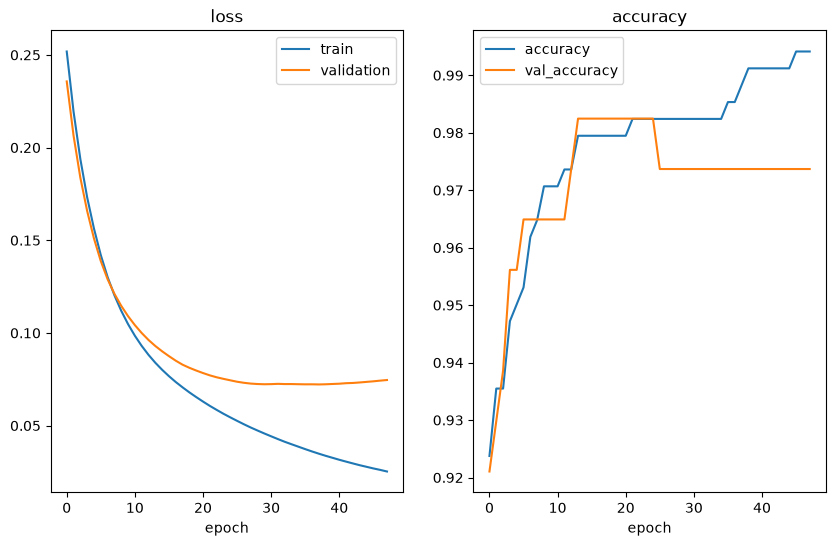

In [28]:
plt.figure(figsize=(10,6))
plt.subplot(1,2,1)
plt.plot(hist["loss"],label="train")
plt.plot(hist["val_loss"],label="validation")
plt.xlabel("epoch")
plt.title("loss")
plt.legend()
plt.subplot(1,2,2)
plt.plot(hist["accuracy"],label="accuracy")
plt.plot(hist["val_accuracy"],label="val_accuracy")
plt.xlabel("epoch")
plt.title("accuracy")
plt.legend()
plt.show()

Evaluate on test set


In [29]:
test_loss,test_accuracy=model.evaluate(x_test,y_test)
print("Test loss",test_loss)
print("Test Accuracy",test_accuracy)

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.9825 - loss: 0.0874
Test loss 0.0874045267701149
Test Accuracy 0.9824561476707458


In [34]:
y_prob=model.predict(x_test).ravel()

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step


In [35]:
y_prob

array([0.00006098, 0.99999887, 0.03885046, 0.65668094, 0.36460227,
       0.00127626, 0.92560023, 0.00049239, 0.00017955, 0.00147433,
       0.98184377, 0.00000846, 0.9999988 , 0.00312915, 0.00167939,
       0.00001463, 0.03897186, 0.00082276, 0.28513378, 0.0001109 ,
       0.01007631, 0.00142907, 0.99999547, 0.99960655, 0.5785211 ,
       0.00008894, 0.00051653, 0.82454365, 0.9941623 , 0.997455  ,
       0.999959  , 0.00188302, 0.9998395 , 0.9998001 , 0.00046386,
       0.0133377 , 0.00227465, 0.00001123, 0.9985587 , 0.0119583 ,
       0.00001438, 0.00027392, 0.7616948 , 0.00137014, 0.02617227,
       0.98298824, 0.08221056, 0.96146196, 0.00057859, 0.00016138,
       0.9999995 , 0.99845654, 0.00927827, 0.00042416, 0.00135344,
       0.98772186, 0.08130436, 0.00000041, 0.00069412, 0.9999997 ,
       0.01055015, 0.00606403, 0.99177736, 0.00000283, 0.04014856,
       0.00260341, 0.9997493 , 0.9999332 , 0.03075298, 0.9745121 ,
       0.00010018, 0.99999917, 0.9998173 , 0.00014189, 0.00011

In [43]:
y_pred= (y_prob >= 0.5).astype("int")

In [44]:
y_pred

array([0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       1, 1, 1, 0, 0, 1, 1, 1, 1, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0,
       0, 1, 0, 1, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0,
       1, 1, 0, 1, 0, 1, 1, 0, 0, 0, 0, 1, 0, 1, 1, 1, 0, 0, 0, 0, 1, 0,
       1, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0,
       0, 0, 1, 1])

Confusion Matrix

In [46]:
cm=confusion_matrix(y_test,y_pred)

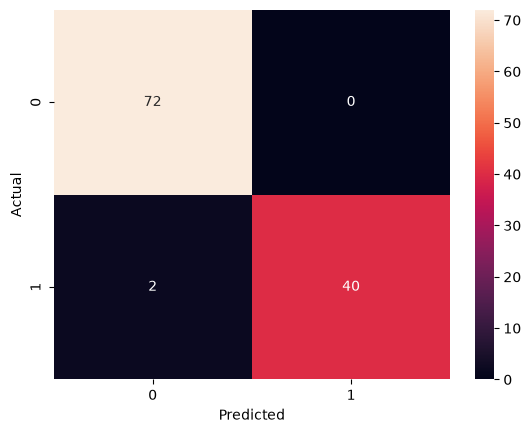

In [51]:
sns.heatmap(cm,annot=True)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [52]:
classificationreport=classification_report(y_test,y_pred)

In [55]:
print(classificationreport)

              precision    recall  f1-score   support

           0       0.97      1.00      0.99        72
           1       1.00      0.95      0.98        42

    accuracy                           0.98       114
   macro avg       0.99      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



ROC CURVE & AUC

In [58]:
auc=roc_auc_score(y_test,y_prob)


In [59]:
print(auc)

0.9947089947089948


In [60]:
fpr,tpr,threshold=roc_curve(y_test,y_prob)

In [61]:
print(fpr,tpr,threshold)

[0.         0.         0.         0.08333333 0.08333333 0.13888889
 0.13888889 1.        ] [0.         0.02380952 0.95238095 0.95238095 0.97619048 0.97619048
 1.         1.        ] [       inf 1.         0.5323807  0.14355341 0.1409568  0.04014856
 0.03897186 0.00000001]


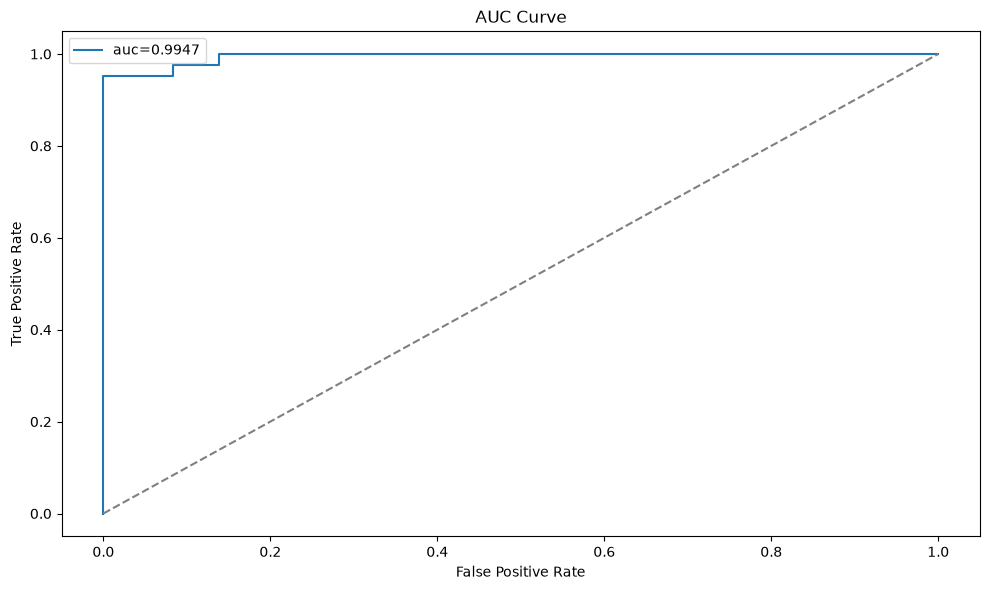

In [64]:
plt.figure(figsize=(10,6))
plt.plot(fpr,tpr,label=f"auc={auc:.4f}")
plt.plot([0,1],[0,1],"--",color="gray")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.title("AUC Curve")
plt.tight_layout()
plt.show()


Save the Model and the Scaler


In [65]:
import joblib

# Save the model
model.save("brest_cancer_model.keras")
joblib.dump(scaler, "scaler.joblib")
print("Saved : brest_cancer_model.keras")

Saved : brest_cancer_model.keras
